In [76]:
#### Initialization
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

###Implement equations of motion into state vector and its derivative

def dynamics(t,X,tau, params):

    m = params["m"]
    g = params["g"]
    L = params["L"]
    Ixx = params["Ixx"]
    Iyy = params["Iyy"]
    Izz = params["Izz"]
    kF = params["kF"]
    kM = params["kM"]
    Jr = params["Jr"]
    
    x,y,z = X[0:3]

    xdot, ydot, zdot = X[3:6]

    phi, theta, psi = X[6:9]

    p, q, r = X[9:12]

    omega1, omega2, omega3, omega4 = X[12:16]

    Xdot = np.zeros(16)

    ###Translational Dynamics

    Xdot[0:3] = [xdot, ydot, zdot]

    F1 = kF * omega1**2
    F2 = kF * omega2**2
    F3 = kF * omega3**2
    F4 = kF * omega4**2

    M1 = kM * omega1**2
    M2 = kM * omega2**2
    M3 = kM * omega3**2
    M4 = kM * omega4**2

    gamma = kM/kF

    T = F1 + F2 + F3 + F4

    xddot = (T/m)*(np.sin(theta)*np.cos(phi)*np.cos(psi) + np.sin(psi)*np.sin(phi))

    yddot = (T/m)*(np.sin(theta)*np.cos(phi)*np.sin(psi) - np.cos(psi)*np.sin(phi))

    zddot = (T/m)*np.cos(theta)*np.cos(phi) - g

    Xdot[3:6] = [xddot, yddot, zddot]

    ###Rotational Dynamics

    pdot = (L*kF*(omega2**2 - omega4**2) + q*r*(Iyy - Izz)) / Ixx

    qdot = (L*kF*(omega3**2 - omega1**2) + r*p*(Izz - Ixx)) / Iyy

    rdot = (kM*(omega1**2 - omega2**2 + omega3**2 - omega4**2) + p*q*(Ixx - Iyy)) / Izz

    Xdot[9:12] = [pdot, qdot, rdot]

    phidot = p + q*np.sin(phi)*np.tan(theta) + r*np.cos(phi)*np.tan(theta)

    thetadot = q*np.cos(phi) - r*np.sin(phi)

    psidot = (q*np.sin(phi) + r*np.cos(phi))/(np.cos(theta))

    Xdot[6:9] = [phidot, thetadot, psidot]

    ### Rotor Dynamics

    omega1dot = (tau[0] - kM*omega1**2) / Jr
    omega2dot = (tau[1] - kM*omega2**2) / Jr
    omega3dot = (tau[2] - kM*omega3**2) / Jr
    omega4dot = (tau[3] - kM*omega4**2) / Jr

    Xdot[12:16] = [omega1dot, omega2dot, omega3dot, omega4dot]
    
    return Xdot







def plot_6dof(sol, title, filename):

    fig, axs = plt.subplots(2, 3, figsize=(14, 8), sharex=True)

    positions = ["$x$", "$y$", "$z$"]
    angles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

    # Shared position limits
    pos_min = np.min(sol.y[0:3])
    pos_max = np.max(sol.y[0:3])
    pos_pad = max(0.1*(pos_max - pos_min), 0.1)

    # Shared angle limits
    angle_data = np.degrees(sol.y[6:9])
    angle_data[2] = angle_data[2] % 360
    angle_min = np.min(angle_data)
    angle_max = np.max(angle_data)
    angle_pad = max(0.1*(angle_max - angle_min), 5.0)

    for i in range(3):
        # Position
        axs[0, i].plot(sol.t, sol.y[i])
        axs[0, i].set_title(f"{positions[i]} Position", fontsize=20)
        axs[0, i].set_xlabel("Time (s)")
        axs[0, i].set_ylim(pos_min - pos_pad, pos_max + pos_pad)
        axs[0, i].grid(True)

        # Euler angles
        axs[1, i].plot(sol.t, angle_data[i])
        axs[1, i].set_title(angles[i], fontsize=20)
        axs[1, i].set_xlabel("Time (s)")
        axs[1, i].set_ylim(angle_min - angle_pad, angle_max + angle_pad)
        axs[1, i].grid(True)

    axs[0, 0].set_ylabel("Position (m)", fontsize=18)
    axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

    for ax in axs.flat:
        ax.tick_params(axis="both", labelsize=15)
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_xlim(sol.t[0], sol.t[-1])

    fig.suptitle(title, fontsize=25)
    plt.tight_layout()
    fig.savefig(filename, bbox_inches="tight")
    plt.show()






In [77]:
###Physical Parameters

params = {
    "m": 1.5,
    "g": 9.81,
    "L": 0.22,
    "Ixx": 0.018,
    "Iyy": 0.018,
    "Izz": 0.030,
    "kF": 1.0e-5,
    "kM": 1.5e-7,
    "Jr": 8.0e-5
}



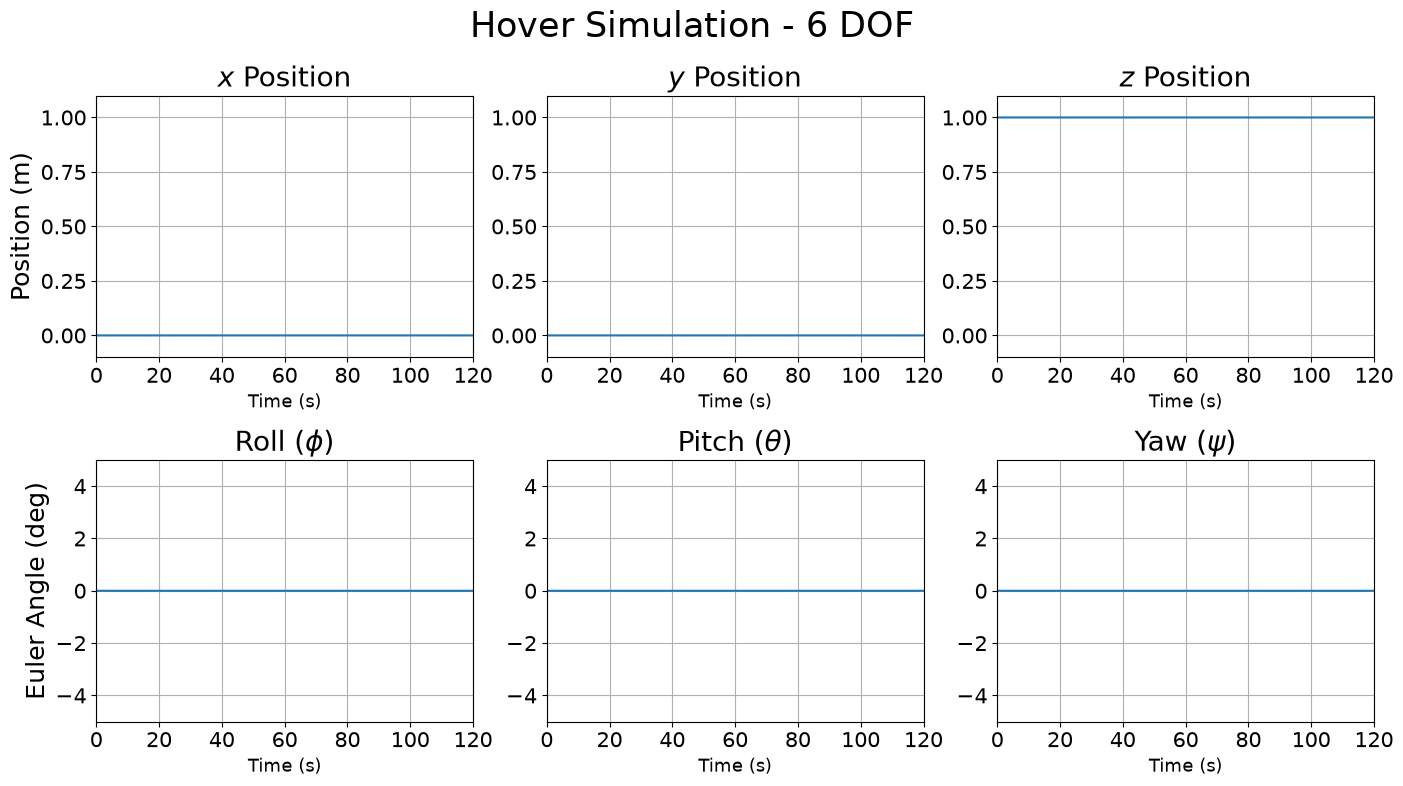

In [78]:
###Hover Case
# Equilibrium hover conditions

omega_hover = np.sqrt(
    params["m"] * params["g"] / (4 * params["kF"])
)

tau_hover = params["kM"] * omega_hover**2

X0_hover = np.zeros(16)

X0_hover[2] = 1
X0_hover[12:16] = omega_hover

tau_hover_array = np.full(4, tau_hover)

timespan_hover = (0,120)

sol_hover = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_hover_array, params),
    t_span=timespan_hover,
    y0=X0_hover,
    method="RK45",
    t_eval=np.linspace(0, 120, 1201),
    rtol=1e-8,
    atol=1e-10
)

plot_6dof(sol_hover, "Hover Simulation - 6 DOF", "hover_6dof.pdf")



In [79]:
print("Initial altitude:", sol_hover.y[2, 0])
print("Final altitude:", sol_hover.y[2, -1])
print("Minimum altitude:", np.min(sol_hover.y[2]))
print("Maximum altitude error:", np.max(np.abs(sol_hover.y[2] - 1.0)))

Initial altitude: 1.0
Final altitude: 0.9999999999744204
Minimum altitude: 0.9999999999744204
Maximum altitude error: 2.557964950966607e-11


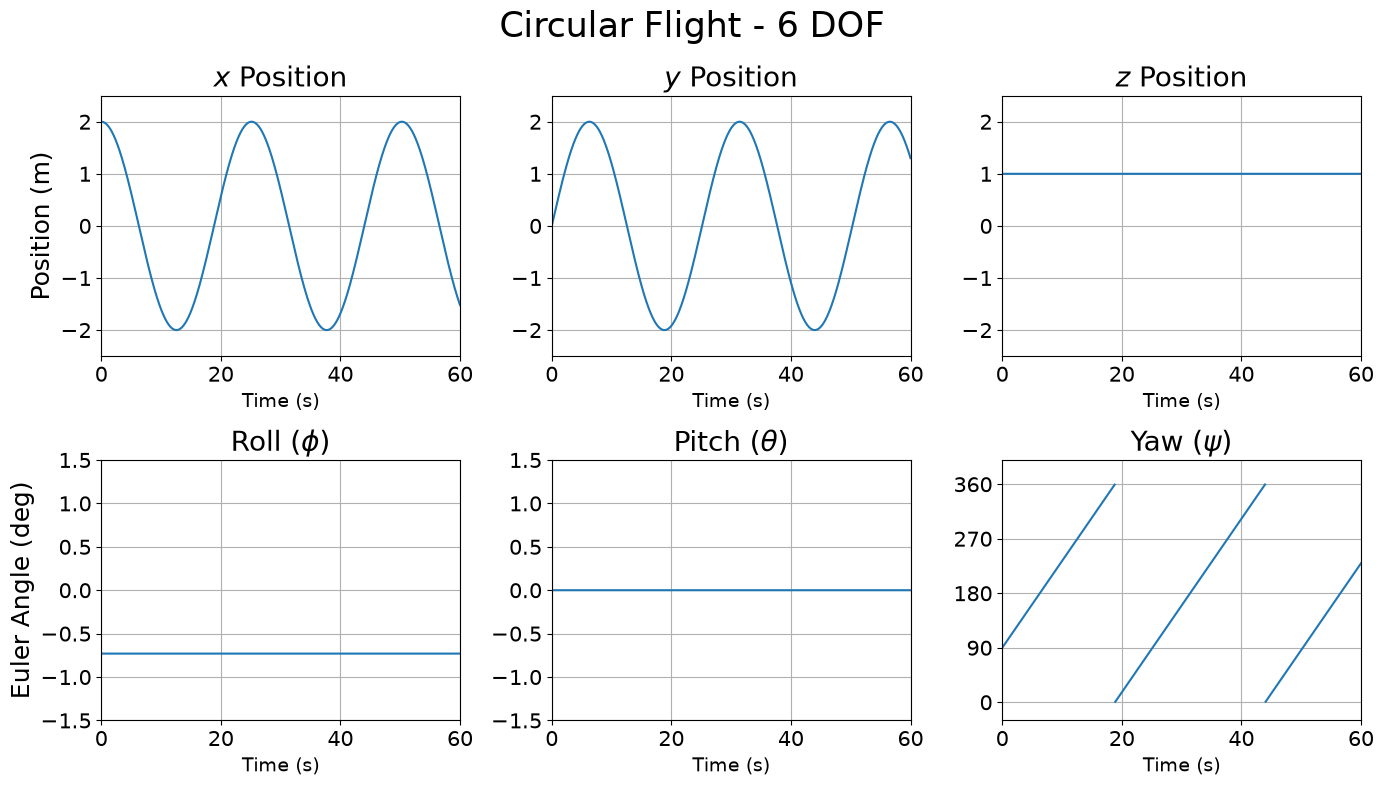

In [80]:
### Performance Test 2: Circular Flight

R_circle = 2.0
v_circle = 0.5
z_circle = 1.0

Omega_circle = v_circle / R_circle
ac_circle = v_circle**2 / R_circle

# Required inward bank angle
phi_circle = -np.arctan(ac_circle / params["g"])

# Initial state
X0_circle = np.zeros(16)

# Initial position
X0_circle[0:3] = [R_circle, 0, z_circle]

# Initial translational velocity
X0_circle[3:6] = [0, v_circle, 0]

# Initial orientation
X0_circle[6:9] = [phi_circle, 0, np.pi/2]

# Initial body angular velocity
X0_circle[9:12] = [
    0,
    Omega_circle*np.sin(phi_circle),
    Omega_circle*np.cos(phi_circle)
]
### Circular Flight Rotor Speeds

T_circle = params["m"] * params["g"] / np.cos(phi_circle)

q0 = X0_circle[10]
r0 = X0_circle[11]

omega_sq = np.array([
    T_circle / (4 * params["kF"]),

    T_circle / (4 * params["kF"])
    + q0*r0*(params["Izz"] - params["Iyy"])
    / (2 * params["L"] * params["kF"]),

    T_circle / (4 * params["kF"]),

    T_circle / (4 * params["kF"])
    - q0*r0*(params["Izz"] - params["Iyy"])
    / (2 * params["L"] * params["kF"])
])

assert np.all(omega_sq >= 0)

omega_circle = np.sqrt(omega_sq)

X0_circle[12:16] = omega_circle

### Circular Flight Motor Torques

tau_circle = params["kM"] * omega_circle**2

t_span_circle = (0, 60)

sol_circle = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_circle, params),
    t_span=t_span_circle,
    y0=X0_circle,
    method="RK45",
    t_eval=np.linspace(0, 60, 1201),
    rtol=1e-8,
    atol=1e-10
)


# Circular Flight - 6 DOF Plots


# Circular Flight - 6 DOF Plots

fig, axs = plt.subplots(2, 3, figsize=(14, 8))

t = sol_circle.t
positions = sol_circle.y[0:3]
angles = np.degrees(sol_circle.y[6:9])

# Wrap yaw between 0 and 360 degrees
yaw = angles[2] % 360

# Break the line at yaw wraparound to avoid vertical jumps
yaw_plot = yaw.copy()
yaw_plot[np.where(np.abs(np.diff(yaw)) > 180)[0] + 1] = np.nan

# Position plots
position_titles = ["$x$ Position", "$y$ Position", "$z$ Position"]

for i in range(3):
    axs[0, i].plot(t, positions[i])
    axs[0, i].set_title(position_titles[i], fontsize=20)
    axs[0, i].set_ylim(-2.5, 2.5)
    axs[0, i].grid(True)

# Euler angle plots
angle_titles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

for i in range(3):
    data = yaw_plot if i == 2 else angles[i]
    axs[1, i].plot(t, data)
    axs[1, i].set_title(angle_titles[i], fontsize=20)
    axs[1, i].grid(True)

    if i < 2:
        axs[1, i].set_ylim(-1.5, 1.5)
    else:
        axs[1, i].set_ylim(-30, 400)
        axs[1, i].set_yticks([0, 90, 180, 270, 360])

# Y-axis labels
axs[0, 0].set_ylabel("Position (m)", fontsize=18)
axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

# Formatting for all six plots
for ax in axs.flat:
    ax.set_xlabel("Time (s)", fontsize=14)
    ax.set_xlim(t[0], t[-1])
    ax.set_xticks(np.arange(0, 61, 20))
    ax.tick_params(axis="both", labelsize=15)

fig.suptitle("Circular Flight - 6 DOF", fontsize=25)

plt.tight_layout()
fig.savefig("circle_6dof.pdf", bbox_inches="tight")
plt.show()



In [81]:
print("Roll:", np.degrees(sol_circle.y[6, 0]))
print("Pitch:", np.degrees(sol_circle.y[7, 0]))
print("Yaw:", np.degrees(sol_circle.y[8, 0]))

print("Final roll:", np.degrees(sol_circle.y[6, -1]))
print("Final pitch:", np.degrees(sol_circle.y[7, -1]))

Roll: -0.7300290385619328
Pitch: 0.0
Yaw: 90.0
Final roll: -0.7300290385769308
Final pitch: -4.89333101716528e-12


Initial speed: 0.5 m/s
Final speed: 0.500000000024143 m/s
Average speed: 0.49999999996461186 m/s
Maximum speed error: 2.9216640218265866e-10 m/s


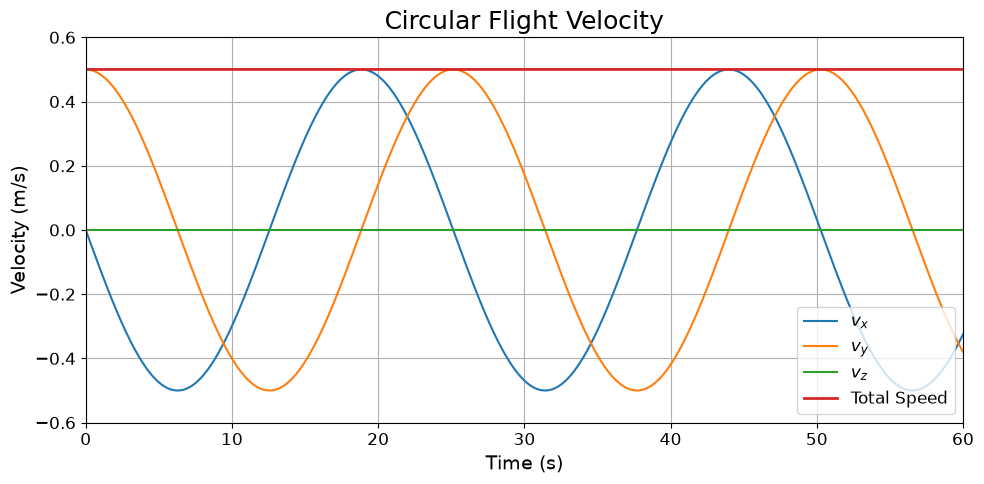

In [82]:
vx = sol_circle.y[3]
vy = sol_circle.y[4]
vz = sol_circle.y[5]

speed = np.sqrt(vx**2 + vy**2 + vz**2)

print("Initial speed:", speed[0], "m/s")
print("Final speed:", speed[-1], "m/s")
print("Average speed:", np.mean(speed), "m/s")
print("Maximum speed error:", np.max(np.abs(speed - 0.5)), "m/s")


fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(sol_circle.t, vx, label=r"$v_x$")
ax.plot(sol_circle.t, vy, label=r"$v_y$")
ax.plot(sol_circle.t, vz, label=r"$v_z$")
ax.plot(sol_circle.t, speed, label="Total Speed", linewidth=2)

ax.set_xlabel("Time (s)", fontsize=14)
ax.set_ylabel("Velocity (m/s)", fontsize=14)
ax.set_title("Circular Flight Velocity", fontsize=18)

ax.set_xlim(sol_circle.t[0], sol_circle.t[-1])
ax.set_ylim(-0.6, 0.6)
ax.tick_params(axis="both", labelsize=12)

ax.legend()
ax.grid(True)

plt.tight_layout()
fig.savefig("circle_velocity.pdf", bbox_inches="tight")
plt.show()


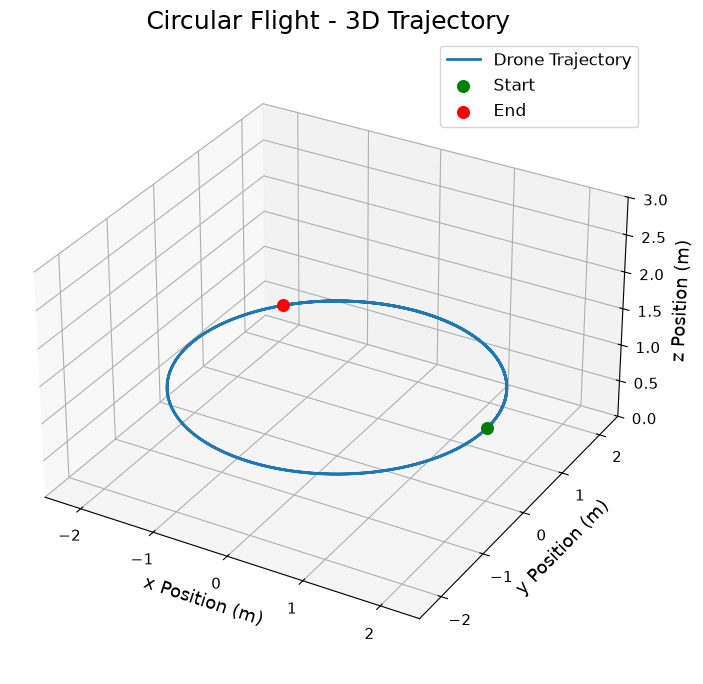

In [84]:

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot the 3D trajectory
ax.plot(
    sol_circle.y[0],
    sol_circle.y[1],
    sol_circle.y[2],
    linewidth=2,
    label="Drone Trajectory"
)

# Mark initial and final positions
ax.scatter(*sol_circle.y[0:3, 0], color="green", s=70, label="Start")
ax.scatter(*sol_circle.y[0:3, -1], color="red", s=70, label="End")

# Set axis limits
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_zlim(0, 3)

# Set axis scaling proportional to physical dimensions
ax.set_box_aspect((5, 5, 3))

# Labels
ax.set_xlabel("x Position (m)", fontsize=13)
ax.set_ylabel("y Position (m)", fontsize=13)
ax.set_zlabel("z Position (m)", fontsize=13)

ax.set_title("Circular Flight - 3D Trajectory", fontsize=18)
ax.legend()

plt.tight_layout()
plt.savefig("circle_3d.pdf", bbox_inches="tight")
plt.show()


In [103]:
### Performance goal 3

zddot = 0.1

X0_takeoff = np.zeros(16)

omega_accel = np.sqrt(
    params["m"] * (params["g"] + zddot) / (4 * params["kF"])
)
tau_accel = np.full(4, params["kM"] * omega_accel**2)

X0_takeoff[12:16] = omega_accel

def midpoint_event(t, X):
    return X[2] - 0.5

midpoint_event.terminal = True
midpoint_event.direction = 1

sol_accel = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_accel, params),
    t_span=(0, 20),
    y0=X0_takeoff,
    events=midpoint_event,
    max_step=0.05,
    rtol=1e-9,
    atol=1e-11
)

assert sol_accel.success and len(sol_accel.t_events[0]) > 0

# Phase 2: Deceleration
X0_decel = sol_accel.y[:, -1].copy()

omega_decel = np.sqrt(
    params["m"] * (params["g"] - zddot) / (4 * params["kF"])
)
tau_decel = np.full(4, params["kM"] * omega_decel**2)

# Change rotor speeds but preserve position and velocity
X0_decel[12:16] = omega_decel

# Stop decelerating when vertical velocity reaches zero
def stop_event(t, X):
    return X[5]

stop_event.terminal = True
stop_event.direction = -1

sol_decel = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_decel, params),
    t_span=(sol_accel.t[-1], sol_accel.t[-1] + 20),
    y0=X0_decel,
    events=stop_event,
    max_step=0.05,
    rtol=1e-9,
    atol=1e-11
)

assert sol_decel.success and len(sol_decel.t_events[0]) > 0

# Phase 3: Hover
X0_hover_after_takeoff = sol_decel.y[:, -1].copy()

omega_hover = np.sqrt(
    params["m"] * params["g"] / (4 * params["kF"])
)
tau_hover = np.full(4, params["kM"] * omega_hover**2)

X0_hover_after_takeoff[12:16] = omega_hover

sol_hover_after_takeoff = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_hover, params),
    t_span=(sol_decel.t[-1], sol_decel.t[-1] + 2),
    y0=X0_hover_after_takeoff,
    max_step=0.05,
    rtol=1e-9,
    atol=1e-11
)

# Combine all three phases
t_takeoff = np.concatenate([
    sol_accel.t,
    sol_decel.t[1:],
    sol_hover_after_takeoff.t[1:]
])

X_takeoff = np.concatenate([
    sol_accel.y,
    sol_decel.y[:, 1:],
    sol_hover_after_takeoff.y[:, 1:]
], axis=1)

# Verify results
print("Acceleration ends at:", sol_accel.t[-1], "s")
print("Midpoint altitude:", sol_accel.y[2, -1], "m")
print("Deceleration ends at:", sol_decel.t[-1], "s")
print("Final altitude:", X_takeoff[2, -1], "m")
print("Final vertical velocity:", X_takeoff[5, -1], "m/s")


Acceleration ends at: 3.1622776601684137 s
Midpoint altitude: 0.49999999999999994 m
Deceleration ends at: 6.324555320336771 s
Final altitude: 0.9999999999999842 m
Final vertical velocity: -7.09729584130736e-15 m/s


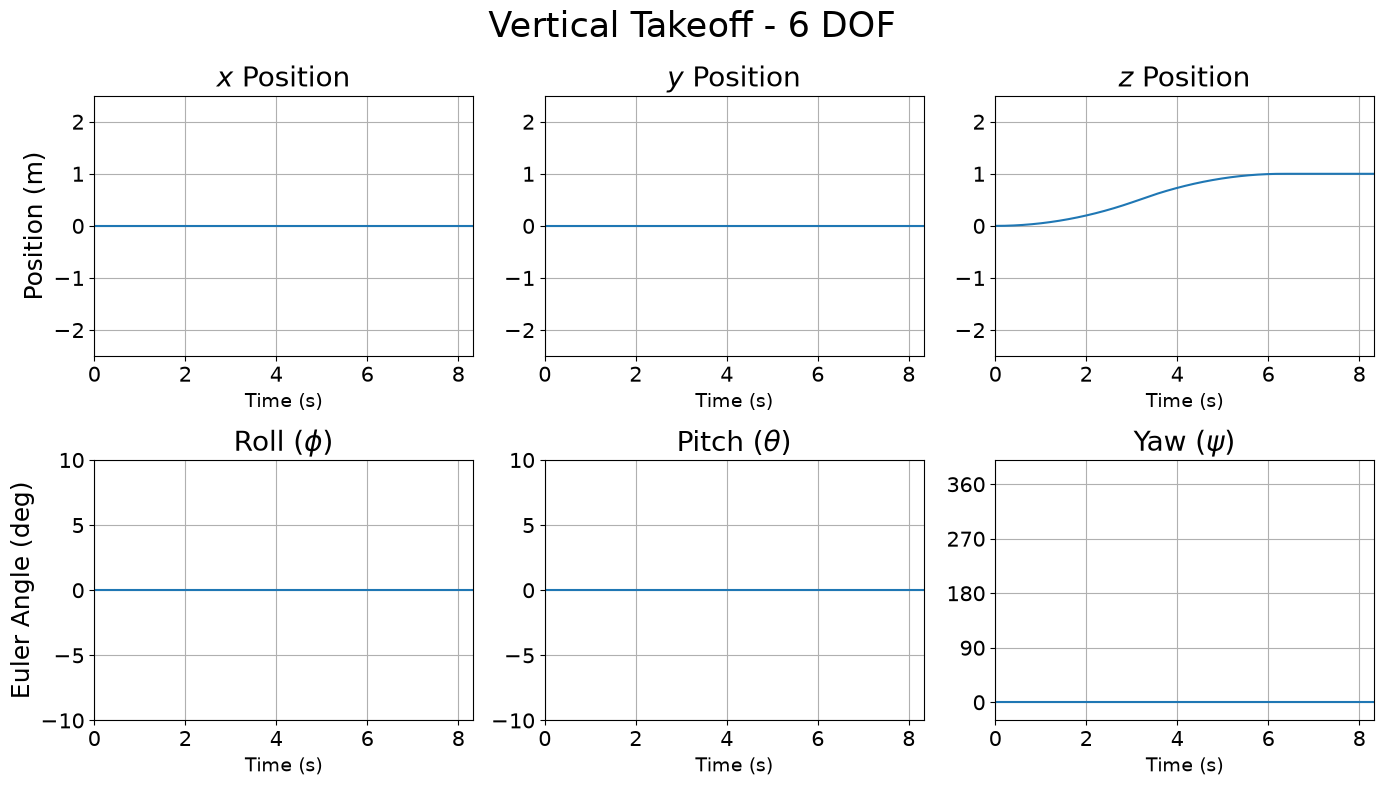

In [122]:

fig, axs = plt.subplots(2, 3, figsize=(14, 8))

t = t_takeoff
positions = X_takeoff[0:3]
angles = np.degrees(X_takeoff[6:9])

# Position plots
position_titles = ["$x$ Position", "$y$ Position", "$z$ Position"]

for i in range(3):
    axs[0, i].plot(t, positions[i])
    axs[0, i].set_title(position_titles[i], fontsize=20)
    axs[0, i].set_ylim(-2.5, 2.5)
    axs[0, i].grid(True)

# Euler angle plots
angle_titles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

for i in range(3):
    axs[1, i].plot(t, angles[i])
    axs[1, i].set_title(angle_titles[i], fontsize=20)
    axs[1, i].grid(True)

    if i < 2:
        axs[1, i].set_ylim(-10, 10)
    else:
        axs[1, i].set_ylim(-30, 400)
        axs[1, i].set_yticks([0, 90, 180, 270, 360])

# Y-axis labels
axs[0, 0].set_ylabel("Position (m)", fontsize=18)
axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

# Formatting
for ax in axs.flat:
    ax.set_xlabel("Time (s)", fontsize=14)
    ax.set_xlim(t[0], t[-1])
    ax.tick_params(axis="both", labelsize=15)

fig.suptitle("Vertical Takeoff - 6 DOF", fontsize=25)

plt.tight_layout()
fig.savefig("takeoff_6dof.pdf", bbox_inches="tight")
plt.show()


In [126]:
def pitch_motor_torques(theta, q, theta_ddot, params):
    m = params["m"]
    g = params["g"]
    kF = params["kF"]
    kM = params["kM"]
    L = params["L"]
    Iyy = params["Iyy"]
    Jr = params["Jr"]

    # Squared rotor speeds required for thrust and pitching
    omega_sq = m * g / (4 * kF * np.cos(theta))
    delta = Iyy * theta_ddot / (2 * L * kF)

    omega = np.sqrt([
        omega_sq - delta,
        omega_sq,
        omega_sq + delta,
        omega_sq
    ])

    # Rate of change of squared rotor speed
    omega_sq_dot = (
        m * g / (4 * kF)
        * np.sin(theta) / np.cos(theta)**2 * q
    )

    omega_dot = omega_sq_dot / (2 * omega)

    # Motor torques
    tau = Jr * omega_dot + kM * omega**2

    return omega, tau


# Time intervals and angular acceleration coefficients
phases = [
    (0.00, 0.25,  16),
    (0.25, 0.50, -16),
    (0.50, 2.00,   0),
    (2.00, 2.50,  -8),
    (2.50, 3.00,   8),
    (3.00, 4.50,   0),
    (4.50, 4.75,  16),
    (4.75, 5.00, -16)
]

def run_translation(theta_max, X_initial):
    X = X_initial.copy()
    solutions = []

    for t0, tf, coefficient in phases:
        theta_ddot = coefficient * theta_max

        # Set rotor speeds at the beginning of each phase
        omega, _ = pitch_motor_torques(
            X[7], X[10], theta_ddot, params
        )
        X[12:16] = omega

        # Integrate the equations of motion
        def rhs(t, X):
            _, tau = pitch_motor_torques(
                X[7], X[10], theta_ddot, params
            )
            return dynamics(t, X, tau, params)

        sol = solve_ivp(
            rhs, (t0, tf), X,
            max_step=0.025,
            rtol=1e-9,
            atol=1e-11
        )

        solutions.append(sol)
        X = sol.y[:, -1].copy()

    return X, solutions


from scipy.optimize import root_scalar

# Initial horizontal position
x0 = sol_hover_after_takeoff.y[0, -1]

# Difference between simulated and desired displacement
def position_error(theta_max):
    X_final, _ = run_translation(theta_max)
    return X_final[0] - x0 - 5.0

# Find maximum pitch angle
result = root_scalar(
    position_error,
    bracket=[np.deg2rad(1), np.deg2rad(15)],
    method="brentq"
)

theta_max = result.root

# Simulate again using the calculated angle
X_final, solutions = run_translation(theta_max)

print(f"Maximum pitch: {np.rad2deg(theta_max):.6f} deg")
print(f"Final x: {X_final[0]:.6f} m")
print(f"Final vx: {X_final[3]:.6f} m/s")
print(f"Final z: {X_final[2]:.6f} m")
print(f"Final pitch: {np.rad2deg(X_final[7]):.6f} deg")
print(f"Final q: {X_final[10]:.6f} rad/s")


TypeError: run_translation() missing 1 required positional argument: 'X_initial'

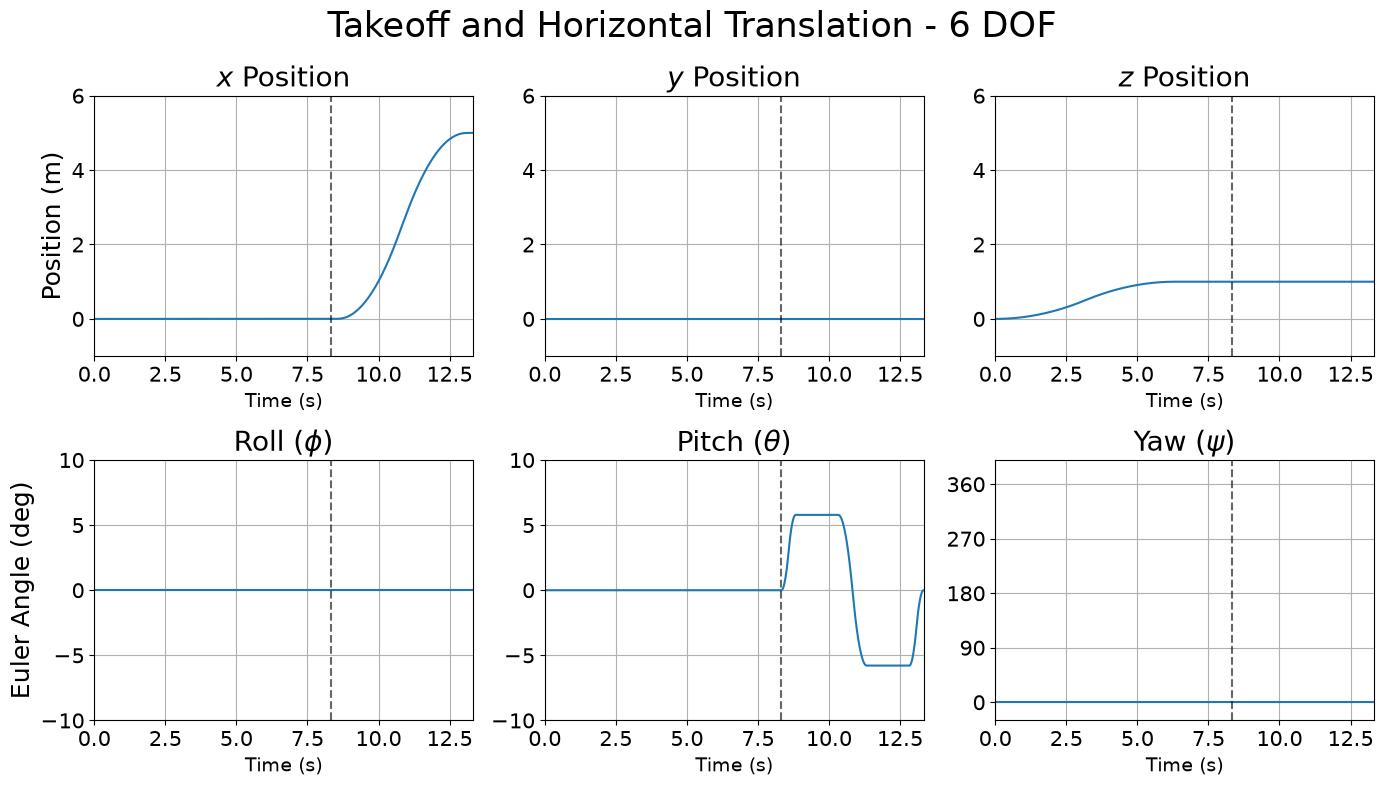

In [127]:

# Combine the takeoff phases
takeoff_solutions = [
    sol_accel,
    sol_decel,
    sol_hover_after_takeoff
]

t_full = np.concatenate([
    sol.t if i == 0 else sol.t[1:]
    for i, sol in enumerate(takeoff_solutions)
])

X_full = np.concatenate([
    sol.y if i == 0 else sol.y[:, 1:]
    for i, sol in enumerate(takeoff_solutions)
], axis=1)

# Shift horizontal translation to begin after takeoff
t_start = t_full[-1]

t_horizontal = np.concatenate([
    sol.t if i == 0 else sol.t[1:]
    for i, sol in enumerate(solutions)
]) + t_start

X_horizontal = np.concatenate([
    sol.y if i == 0 else sol.y[:, 1:]
    for i, sol in enumerate(solutions)
], axis=1)

# Combine into one trajectory
t_full = np.concatenate([t_full, t_horizontal[1:]])
X_full = np.concatenate([X_full, X_horizontal[:, 1:]], axis=1)





fig, axs = plt.subplots(2, 3, figsize=(14, 8))

t = t_full
positions = X_full[0:3]
angles = np.degrees(X_full[6:9])

# Position plots
position_titles = ["$x$ Position", "$y$ Position", "$z$ Position"]

for i in range(3):
    axs[0, i].plot(t, positions[i])
    axs[0, i].set_title(position_titles[i], fontsize=20)
    axs[0, i].grid(True)
    axs[0, i].set_ylim(-1, 6)

# Euler angle plots
angle_titles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

for i in range(3):
    axs[1, i].plot(t, angles[i])
    axs[1, i].set_title(angle_titles[i], fontsize=20)
    axs[1, i].grid(True)
    if i < 2:
        axs[1, i].set_ylim(-10, 10)
    else:
        axs[1, i].set_ylim(-30, 400)
        axs[1, i].set_yticks([0, 90, 180, 270, 360])

# Y-axis labels
axs[0, 0].set_ylabel("Position (m)", fontsize=18)
axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

# Formatting for all six plots
for ax in axs.flat:
    ax.axvline(t_start, color="black", linestyle="--", alpha=0.6)
    ax.set_xlabel("Time (s)", fontsize=14)
    ax.set_xlim(t[0], t[-1])
    ax.tick_params(axis="both", labelsize=15)

fig.suptitle("Takeoff and Horizontal Translation - 6 DOF", fontsize=25)

plt.tight_layout()
fig.savefig("takeoff_translation_6dof.pdf", bbox_inches="tight")
plt.show()





In [ ]:

# Required yaw angular acceleration
psi_ddot = np.pi / 2

def yaw_motor_inputs(psi_ddot, params):
    m = params["m"]
    g = params["g"]
    kF = params["kF"]
    kM = params["kM"]
    Izz = params["Izz"]

    # Squared rotor speeds for thrust and yaw
    omega_sq = np.array([
        m*g/(4*kF) + Izz*psi_ddot/(4*kM),
        m*g/(4*kF) - Izz*psi_ddot/(4*kM),
        m*g/(4*kF) + Izz*psi_ddot/(4*kM),
        m*g/(4*kF) - Izz*psi_ddot/(4*kM)
    ])

    omega = np.sqrt(omega_sq)

    # Constant rotor speeds within each phase
    tau = kM * omega_sq

    return omega, tau


# Phase 1: Positive yaw acceleration
X0_yaw = X_final.copy()

omega_accel_yaw, tau_accel_yaw = yaw_motor_inputs(
    psi_ddot, params
)

X0_yaw[12:16] = omega_accel_yaw

sol_yaw_accel = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_accel_yaw, params),
    t_span=(0, 1),
    y0=X0_yaw,
    max_step=0.025,
    rtol=1e-9,
    atol=1e-11
)


# Phase 2: Negative yaw acceleration
X0_decel_yaw = sol_yaw_accel.y[:, -1].copy()

omega_decel_yaw, tau_decel_yaw = yaw_motor_inputs(
    -psi_ddot, params
)

X0_decel_yaw[12:16] = omega_decel_yaw

sol_yaw_decel = solve_ivp(
    fun=lambda t, X: dynamics(t, X, tau_decel_yaw, params),
    t_span=(1, 2),
    y0=X0_decel_yaw,
    max_step=0.025,
    rtol=1e-9,
    atol=1e-11
)


# Combine both phases
t_yaw = np.concatenate([
    sol_yaw_accel.t,
    sol_yaw_decel.t[1:]
])

X_yaw = np.concatenate([
    sol_yaw_accel.y,
    sol_yaw_decel.y[:, 1:]
], axis=1)

# Final state
X_final_yaw = sol_yaw_decel.y[:, -1].copy()

X0_hover_after_yaw = X_final_yaw.copy()
X0_hover_after_yaw[12:16] = omega_hover

# Verify results
print(f"Final yaw: {np.rad2deg(X_final_yaw[8]):.6f} deg")
print(f"Final yaw rate: {X_final_yaw[11]:.6f} rad/s")
print(f"Final position: {X_final_yaw[0:3]}")
print(f"Final velocity: {X_final_yaw[3:6]}")


Final yaw: 90.000000 deg
Final yaw rate: 0.000000 rad/s
Final position: [5.0000000e+00 4.3007337e-12 1.0000000e+00]
Final velocity: [1.02662621e-10 8.44661285e-12 3.31302540e-12]


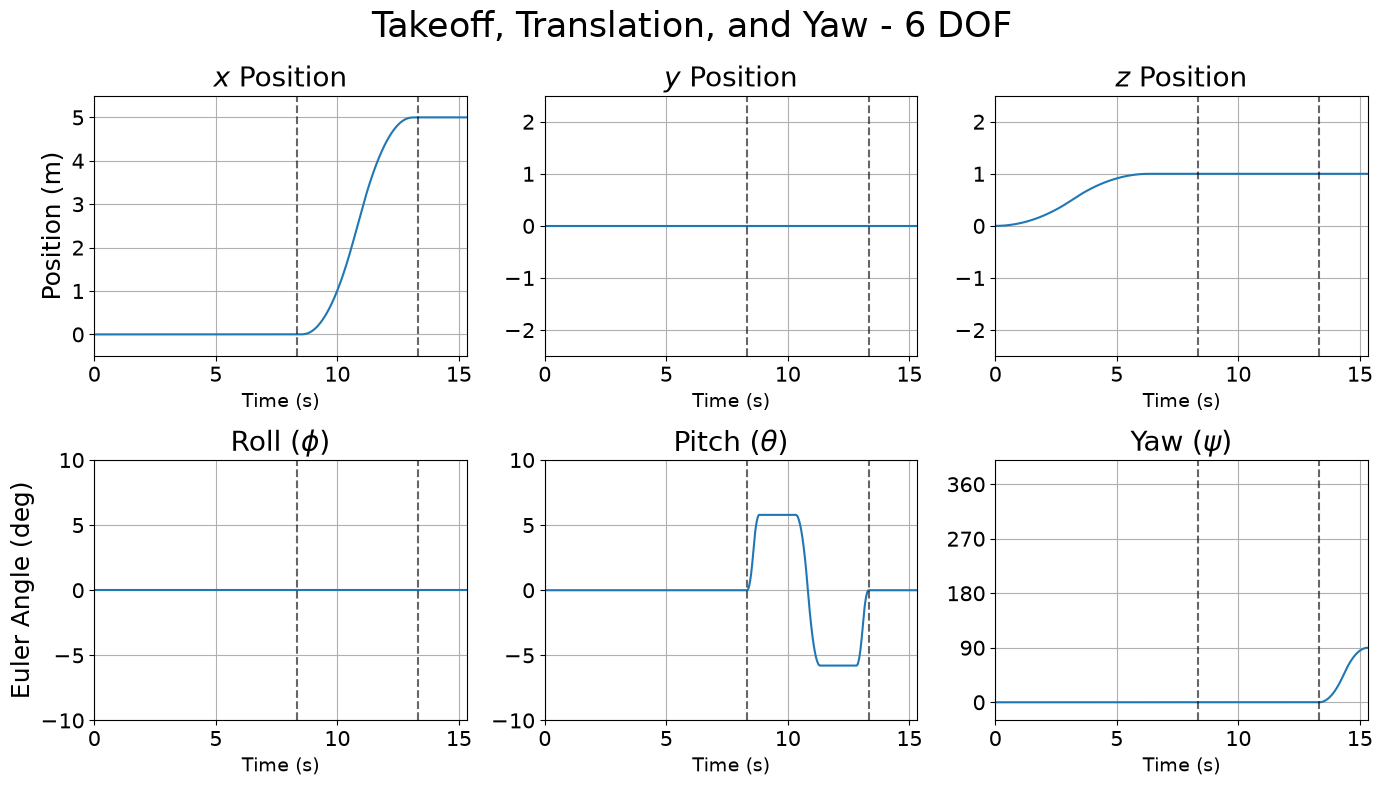

In [124]:

# Combine horizontal translation phases
t_horizontal = np.concatenate([
    sol.t if i == 0 else sol.t[1:]
    for i, sol in enumerate(solutions)
])

X_horizontal = np.concatenate([
    sol.y if i == 0 else sol.y[:, 1:]
    for i, sol in enumerate(solutions)
], axis=1)

# Times when maneuvers begin
t_translation_start = t_takeoff[-1]
t_yaw_start = t_translation_start + t_horizontal[-1]

# Combine takeoff, translation, and yaw
t = np.concatenate([
    t_takeoff,
    t_horizontal[1:] + t_translation_start,
    t_yaw[1:] + t_yaw_start
])

X = np.concatenate([
    X_takeoff,
    X_horizontal[:, 1:],
    X_yaw[:, 1:]
], axis=1)

# Create 6-DOF plots
fig, axs = plt.subplots(2, 3, figsize=(14, 8))

positions = X[0:3]
angles = np.degrees(X[6:9])

# Position plots
position_titles = ["$x$ Position", "$y$ Position", "$z$ Position"]

for i in range(3):
    axs[0, i].plot(t, positions[i])
    axs[0, i].set_title(position_titles[i], fontsize=20)
    axs[0, i].grid(True)

    if i == 0:
        axs[0, i].set_ylim(-0.5, 5.5)
    else:
        axs[0, i].set_ylim(-2.5, 2.5)

# Euler angle plots
angle_titles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

for i in range(3):
    axs[1, i].plot(t, angles[i])
    axs[1, i].set_title(angle_titles[i], fontsize=20)
    axs[1, i].grid(True)

    if i < 2:
        axs[1, i].set_ylim(-10, 10)
    else:
        axs[1, i].set_ylim(-30, 400)
        axs[1, i].set_yticks([0, 90, 180, 270, 360])

# Y-axis labels
axs[0, 0].set_ylabel("Position (m)", fontsize=18)
axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

# Formatting for all six plots
for ax in axs.flat:
    ax.axvline(t_translation_start, color="black",
               linestyle="--", alpha=0.6)
    ax.axvline(t_yaw_start, color="black",
               linestyle="--", alpha=0.6)

    ax.set_xlabel("Time (s)", fontsize=14)
    ax.set_xlim(t[0], t[-1])
    ax.tick_params(axis="both", labelsize=15)

fig.suptitle("Takeoff, Translation, and Yaw - 6 DOF", fontsize=25)

plt.tight_layout()
fig.savefig("takeoff_translation_yaw_6dof.pdf", bbox_inches="tight")
plt.show()


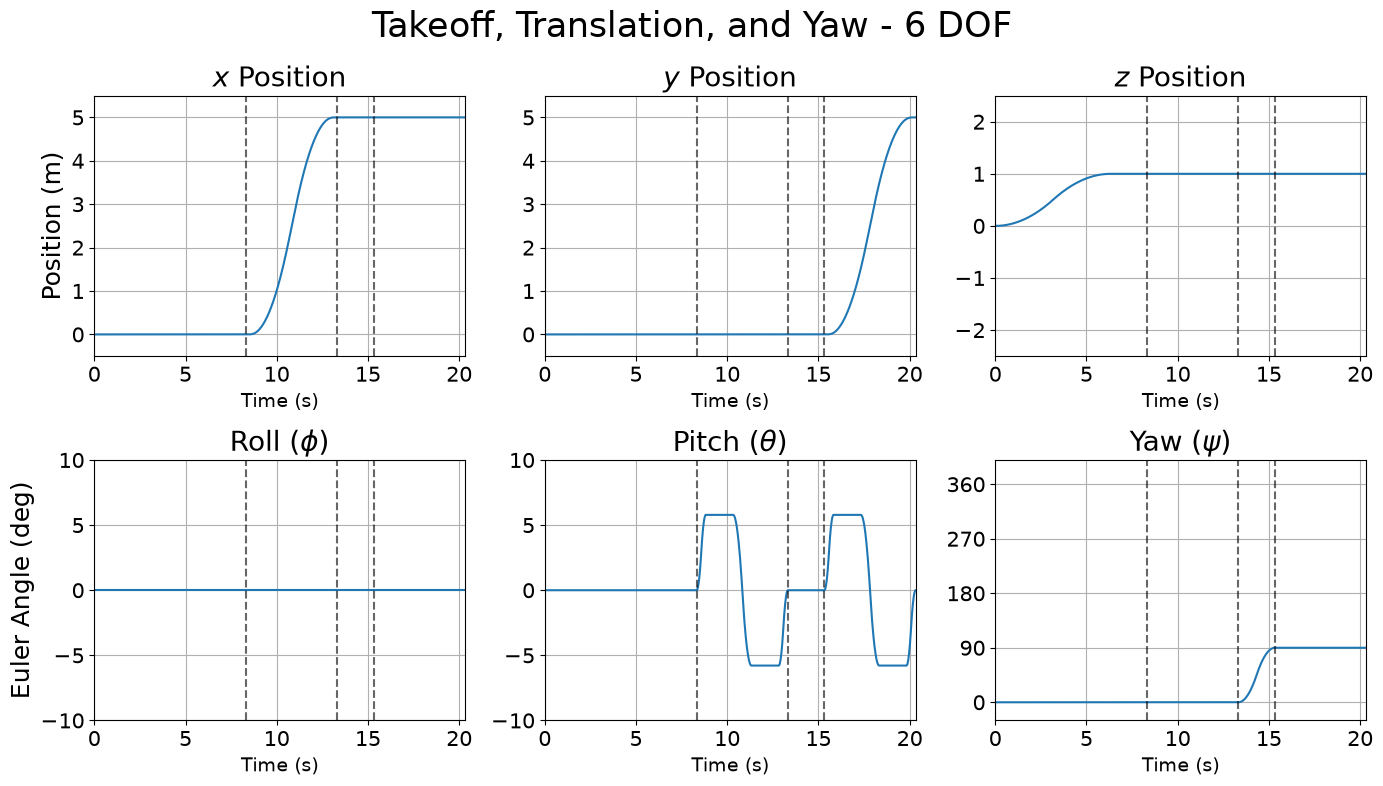

In [129]:

# Second 5 m translation, now in the +y direction
X_final_second, solutions_second = run_translation(
    theta_max, X_final_yaw
)

# Combine first horizontal translation
t_horizontal = np.concatenate([
    sol.t if i == 0 else sol.t[1:]
    for i, sol in enumerate(solutions)
])

X_horizontal = np.concatenate([
    sol.y if i == 0 else sol.y[:, 1:]
    for i, sol in enumerate(solutions)
], axis=1)

# Combine second horizontal translation
t_horizontal_second = np.concatenate([
    sol.t if i == 0 else sol.t[1:]
    for i, sol in enumerate(solutions_second)
])

X_horizontal_second = np.concatenate([
    sol.y if i == 0 else sol.y[:, 1:]
    for i, sol in enumerate(solutions_second)
], axis=1)

# Maneuver start times
t_translation_start = t_takeoff[-1]
t_yaw_start = t_translation_start + t_horizontal[-1]
t_second_start = t_yaw_start + t_yaw[-1]

# Combine all four maneuvers
t = np.concatenate([
    t_takeoff,
    t_horizontal[1:] + t_translation_start,
    t_yaw[1:] + t_yaw_start,
    t_horizontal_second[1:] + t_second_start
])

X = np.concatenate([
    X_takeoff,
    X_horizontal[:, 1:],
    X_yaw[:, 1:],
    X_horizontal_second[:, 1:]
], axis=1)

# Create 6-DOF plots
fig, axs = plt.subplots(2, 3, figsize=(14, 8))

positions = X[0:3]
angles = np.degrees(X[6:9])

# Position plots
position_titles = ["$x$ Position", "$y$ Position", "$z$ Position"]

for i in range(3):
    axs[0, i].plot(t, positions[i])
    axs[0, i].set_title(position_titles[i], fontsize=20)
    axs[0, i].set_ylim(-0.5, 5.5) if i < 2 else axs[0, i].set_ylim(-2.5, 2.5)
    axs[0, i].grid(True)

# Euler angle plots
angle_titles = [r"Roll ($\phi$)", r"Pitch ($\theta$)", r"Yaw ($\psi$)"]

for i in range(3):
    axs[1, i].plot(t, angles[i])
    axs[1, i].set_title(angle_titles[i], fontsize=20)
    axs[1, i].grid(True)

    if i < 2:
        axs[1, i].set_ylim(-10, 10)
    else:
        axs[1, i].set_ylim(-30, 400)
        axs[1, i].set_yticks([0, 90, 180, 270, 360])

# Y-axis labels
axs[0, 0].set_ylabel("Position (m)", fontsize=18)
axs[1, 0].set_ylabel("Euler Angle (deg)", fontsize=18)

# Formatting for all six plots
for ax in axs.flat:
    for t_boundary in [t_translation_start, t_yaw_start, t_second_start]:
        ax.axvline(t_boundary, color="black", linestyle="--", alpha=0.6)

    ax.set_xlabel("Time (s)", fontsize=14)
    ax.set_xlim(t[0], t[-1])
    ax.tick_params(axis="both", labelsize=15)

fig.suptitle("Takeoff, Translation, and Yaw - 6 DOF", fontsize=25)

plt.tight_layout()
fig.savefig("takeoff_two_translations_yaw_6dof.pdf", bbox_inches="tight")
plt.show()

